# Обучение классификатора овощей (трек A)

Перед запуском:
1. Панель справа **Input → Add Input**: датасет `vegetable-dataset` (автор preethi866).
2. **Settings → Accelerator**: GPU T4 x2.
3. **Settings → Internet** должен быть включён (в меню пункт называется «Turn off internet»): он нужен для `git clone` и весов ImageNet.

Весь ноутбук (Run All) идёт около 20–25 минут.

In [1]:
REPO = "https://github.com/Abylcor/vegetable-classifier.git"

%cd /kaggle/working
!rm -rf vegetable-classifier && git clone -q {REPO}
%cd vegetable-classifier
!ls
!nvidia-smi -L

/kaggle/working
/kaggle/working/vegetable-classifier
audit_dataset.py  common.py   kaggle_train.ipynb  predict.py  train.py
author_split.csv  gradcam.py  make_splits.py	  splits.csv
GPU 0: Tesla T4 (UUID: GPU-80eb2677-77db-fe4b-4ce3-f61600b35292)
GPU 1: Tesla T4 (UUID: GPU-f24ece5f-b7ce-ebd0-19f5-06a6763b25f8)


## Проверка разбиения на Kaggle (воспроизводимость)
Строим разбиение заново из файлов датасета и сравниваем с `splits.csv` из репозитория. Ожидается `совпадает: 1.0`.

Нужен scikit-learn 1.8 или новее: в более старых версиях (на Kaggle стоит такая) `StratifiedGroupKFold` с `shuffle=True` перемешивает группы с ошибкой и даёт другое, плохо стратифицированное разбиение. Поэтому сначала ставим новую версию.

In [2]:
!pip install -q "scikit-learn>=1.8"
!python make_splits.py --data /kaggle/input --out splits_kaggle.csv
import pandas as pd
a, b = pd.read_csv("splits.csv"), pd.read_csv("splits_kaggle.csv")
key = lambda d: d["label"] + "/" + d["path"].str.split("/").str[-1]
m = a.assign(k=key(a)).merge(b.assign(k=key(b)), on="k")
print("строк:", len(a), len(b), "| сопоставлено:", len(m), "| совпадает:", (m.fold_x == m.fold_y).mean())

Изображений: 3879; по классам: {'Capsicum': 615, 'Carrot': 905, 'Cucumber': 308, 'Potato': 422, 'Raddish': 286, 'Squash': 1343}
Типы файлов: {'photo': 185, 'frame': 3694}
scikit-learn 1.9.1

Изображений / групп по классам и фолдам:
class              fold0         fold1
Capsicum      239 / 2       376 / 2   
Carrot        445 / 3       460 / 3   
Cucumber      175 / 1       133 / 3   
Potato        103 / 1       319 / 1   
Raddish       161 / 1       125 / 1   
Squash        613 / 2       730 / 3   
Групп всего: 23; групп в нескольких фолдах: 0

Записал splits_kaggle.csv
строк: 3879 3879 | сопоставлено: 3879 | совпадает: 1.0


## Наше разбиение: 2 фолда по видео

In [3]:
!python train.py --data /kaggle/input --splits splits.csv --test-fold 0 --out runs/fold0

Устройство: cuda
Пути из таблицы не найдены напрямую, ищу файлы по имени класса и файла...
Проверил 3879 файлов за 270 c
Групп (видео/сцен) одновременно в train и test: 0
train: фолды ['1'], 2143 фото; test: фолд 0, 1736 фото
train по классам: {'Capsicum': 376, 'Carrot': 460, 'Cucumber': 133, 'Potato': 319, 'Raddish': 125, 'Squash': 730}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|███████████████████████████████████████| 20.5M/20.5M [00:00<00:00, 139MB/s]
[head] epoch 1: train loss 0.8733, train acc 0.9071, lr 1.00e-03, 21 c
[head] epoch 2: train loss 0.6356, train acc 0.9841, lr 1.00e-03, 17 c
[full] epoch 1: train loss 0.7343, train acc 0.9529, lr 1.00e-04, 19 c
[full] epoch 2: train loss 0.6346, train acc 0.9883, lr 9.33e-05, 19 c
[full] epoch 3: train loss 0.6156, train acc 0.9944, lr 7.50e-05, 18 c
[full] epoch 4: train loss 0.6052, train acc 0.9944, lr 5

In [4]:
!python train.py --data /kaggle/input --splits splits.csv --test-fold 1 --out runs/fold1

Устройство: cuda
Пути из таблицы не найдены напрямую, ищу файлы по имени класса и файла...
Проверил 3879 файлов за 16 c
Групп (видео/сцен) одновременно в train и test: 0
train: фолды ['0'], 1736 фото; test: фолд 1, 2143 фото
train по классам: {'Capsicum': 239, 'Carrot': 445, 'Cucumber': 175, 'Potato': 103, 'Raddish': 161, 'Squash': 613}
[head] epoch 1: train loss 0.8516, train acc 0.9217, lr 1.00e-03, 13 c
[head] epoch 2: train loss 0.6143, train acc 0.9868, lr 1.00e-03, 12 c
[full] epoch 1: train loss 0.7222, train acc 0.9568, lr 1.00e-04, 13 c
[full] epoch 2: train loss 0.6205, train acc 0.9908, lr 9.33e-05, 13 c
[full] epoch 3: train loss 0.5961, train acc 0.9971, lr 7.50e-05, 13 c
[full] epoch 4: train loss 0.5927, train acc 0.9937, lr 5.00e-05, 13 c
[full] epoch 5: train loss 0.5926, train acc 0.9954, lr 2.50e-05, 13 c
[full] epoch 6: train loss 0.5952, train acc 0.9954, lr 6.70e-06, 13 c

accuracy = 0.9025   macro-F1 = 0.8824
class      precision  recall      f1  support
Capsicum

## Итог по обоим фолдам (out-of-fold)
Каждое из 3879 фото предсказано моделью, которая не видела его видео.

In [5]:
import sys, pandas as pd
sys.path.insert(0, ".")
from train import compute_metrics, print_metrics
from common import CLASSES
oof = pd.concat([pd.read_csv("runs/fold0/preds.csv"), pd.read_csv("runs/fold1/preds.csv")], ignore_index=True)
idx = {c: i for i, c in enumerate(CLASSES)}
print("фото:", len(oof), "| уникальных:", oof.path.nunique())
print_metrics(compute_metrics(oof.label.map(idx).tolist(), oof.pred.map(idx).tolist(), len(CLASSES)))
oof.to_csv("runs/oof_preds.csv", index=False)

фото: 3879 | уникальных: 3879

accuracy = 0.9368   macro-F1 = 0.9199
class      precision  recall      f1  support
Capsicum       0.900   0.948   0.923      615
Carrot         0.998   0.959   0.978      905
Cucumber       0.939   0.951   0.945      308
Potato         0.941   0.751   0.835      422
Raddish        0.801   0.983   0.882      286
Squash         0.949   0.962   0.956     1343

Матрица ошибок (строка = истинный класс, столбец = предсказание):
           Capsicum   Carrot Cucumber   Potato  Raddish   Squash
Capsicum        583        0       15       11        4        2
Carrot            2      868        3        1        9       22
Cucumber         10        0      293        0        0        5
Potato           12        0        0      317       53       40
Raddish           0        2        0        3      281        0
Squash           41        0        1        5        4     1292


## Для сравнения: авторское разбиение final_dataset
Учим на авторском train, проверяем на авторском test. Эта цифра нужна только для отчёта: она показывает, насколько утечка завышает метрику.

In [6]:
!python train.py --data /kaggle/input --splits author_split.csv --train-folds train --test-fold test --out runs/author

Устройство: cuda
Пути из таблицы не найдены напрямую, ищу файлы по имени класса и файла...
Проверил 4578 файлов за 19 c
Групп (видео/сцен) одновременно в train и test: 21
train: фолды ['train'], 3779 фото; test: фолд test, 799 фото
train по классам: {'Capsicum': 590, 'Carrot': 876, 'Cucumber': 295, 'Potato': 416, 'Raddish': 283, 'Squash': 1319}
[head] epoch 1: train loss 0.7531, train acc 0.9354, lr 1.00e-03, 29 c
[head] epoch 2: train loss 0.5955, train acc 0.9878, lr 1.00e-03, 29 c
[full] epoch 1: train loss 0.6696, train acc 0.9558, lr 1.00e-04, 30 c
[full] epoch 2: train loss 0.5911, train acc 0.9886, lr 9.33e-05, 31 c
[full] epoch 3: train loss 0.5750, train acc 0.9947, lr 7.50e-05, 32 c
[full] epoch 4: train loss 0.5727, train acc 0.9974, lr 5.00e-05, 31 c
[full] epoch 5: train loss 0.5711, train acc 0.9958, lr 2.50e-05, 31 c
[full] epoch 6: train loss 0.5683, train acc 0.9952, lr 6.70e-06, 31 c

accuracy = 1.0000   macro-F1 = 1.0000
class      precision  recall      f1  support


## Финальная модель для predict.py
Тот же рецепт, но обучение на всех 3879 фото (тестового фолда нет: качество мы уже оценили выше).

In [7]:
!python train.py --data /kaggle/input --splits splits.csv --test-fold none --out runs/final
!mkdir -p weights && cp runs/final/model.pt weights/model.pt && ls -la weights

Устройство: cuda
Пути из таблицы не найдены напрямую, ищу файлы по имени класса и файла...
Проверил 3879 файлов за 16 c
Групп (видео/сцен) одновременно в train и test: 0
train: фолды ['0', '1'], 3879 фото; test: фолд None, 0 фото
train по классам: {'Capsicum': 615, 'Carrot': 905, 'Cucumber': 308, 'Potato': 422, 'Raddish': 286, 'Squash': 1343}
[head] epoch 1: train loss 0.7543, train acc 0.9356, lr 1.00e-03, 30 c
[head] epoch 2: train loss 0.5970, train acc 0.9848, lr 1.00e-03, 31 c
[full] epoch 1: train loss 0.6525, train acc 0.9642, lr 1.00e-04, 32 c
[full] epoch 2: train loss 0.5925, train acc 0.9887, lr 9.33e-05, 32 c
[full] epoch 3: train loss 0.5733, train acc 0.9956, lr 7.50e-05, 32 c
[full] epoch 4: train loss 0.5679, train acc 0.9966, lr 5.00e-05, 32 c
[full] epoch 5: train loss 0.5698, train acc 0.9954, lr 2.50e-05, 32 c
[full] epoch 6: train loss 0.5675, train acc 0.9964, lr 6.70e-06, 32 c

Сохранено в runs/final/: model.pt, log.csv, metrics.json
total 15968
drwxr-xr-x 2 root

## Grad-CAM
Самые уверенные ошибки (не больше одной на видео) и по одному правильному примеру каждого класса. Для каждого фото используется модель фолда, которая не видела его видео.

12 примеров (6 ошибок) -> runs/gradcam/gradcam_grid.png
 1. ОШИБКА  Squash    -> Capsicum  0.80  Squash/video_20251117_134731
 2. ОШИБКА  Potato    -> Capsicum  0.74  Potato/video_20251113_205825
 3. ОШИБКА  Squash    -> Capsicum  0.73  Squash/video_20251113_210502
 4. ОШИБКА  Cucumber  -> Capsicum  0.67  Cucumber/video_20260101_132322
 5. ОШИБКА  Capsicum  -> Raddish   0.66  Capsicum/video_20251117_134205
 6. ОШИБКА  Carrot    -> Raddish   0.60  Carrot/video_20251113_210803
 7. верно   Capsicum  -> Capsicum  0.76  Capsicum/video_20260101_132853
 8. верно   Carrot    -> Carrot    0.74  Carrot/video_20260101_132606
 9. верно   Cucumber  -> Cucumber  0.69  Cucumber/video_20260101_132322
10. верно   Potato    -> Potato    0.51  Potato/video_20260101_133344
11. верно   Raddish   -> Raddish   0.86  Raddish/video_20251210_230636
12. верно   Squash    -> Squash    0.70  Squash/video_20260101_134905


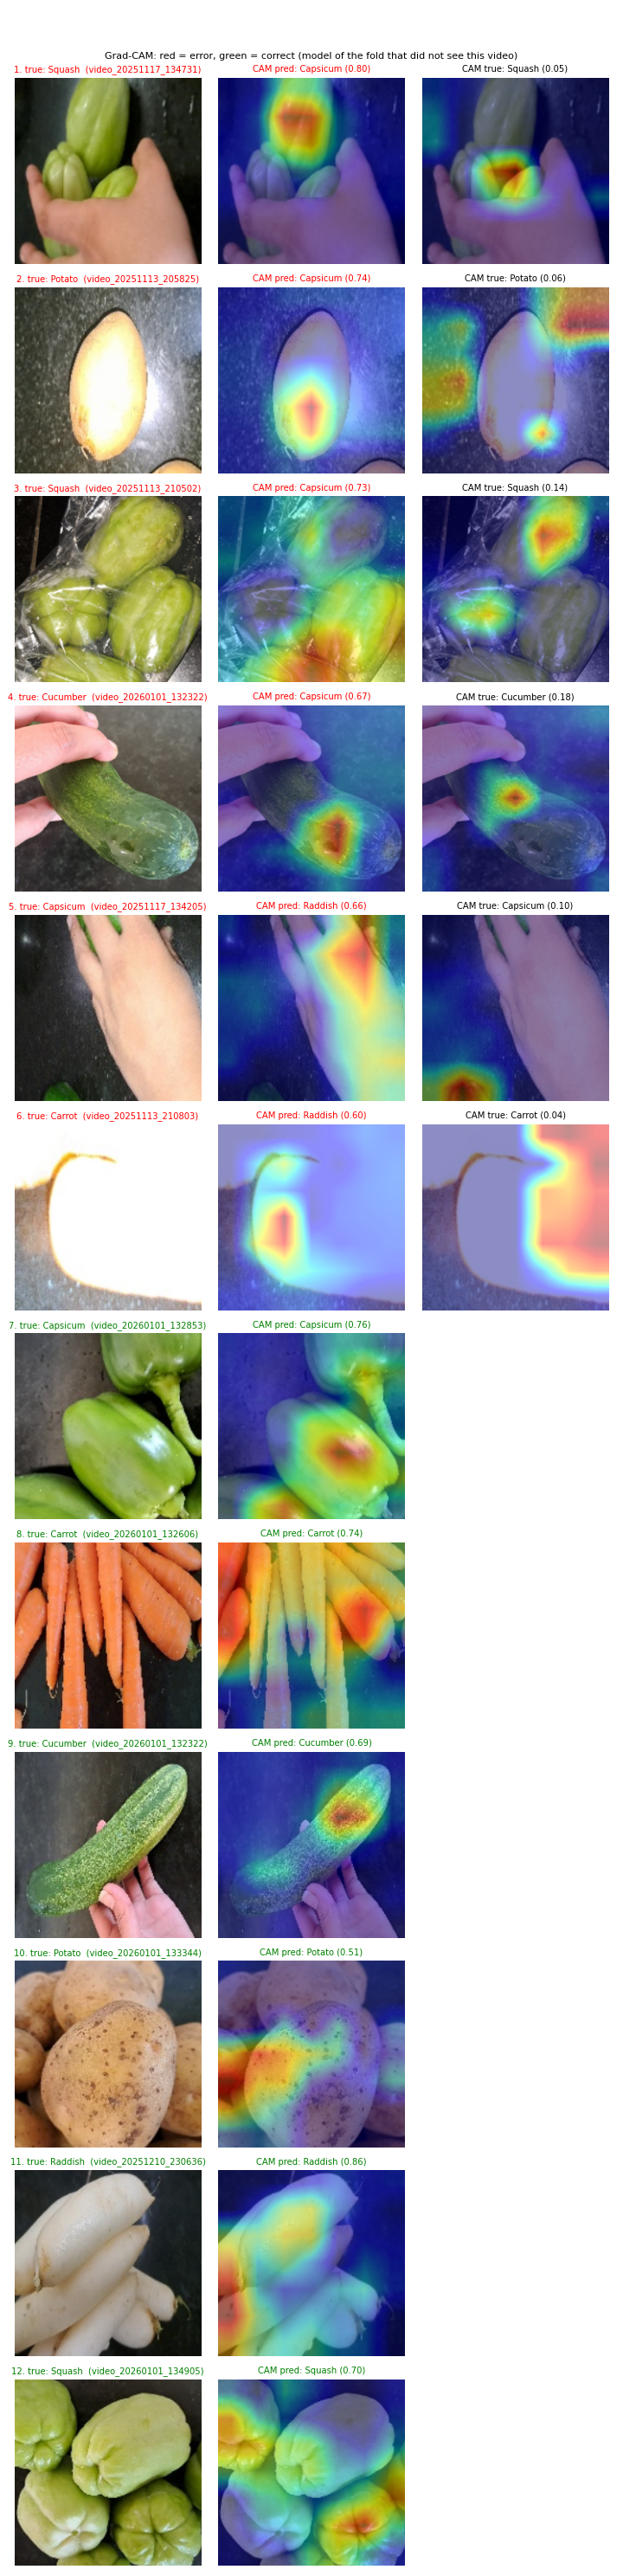

In [8]:
!python gradcam.py --data /kaggle/input --runs runs --out runs/gradcam
from IPython.display import Image, display
display(Image("runs/gradcam/gradcam_grid.png"))

## predict.py на CPU
Проверяем, что скрипт работает как в ТЗ: папка на входе, CSV на выходе, битые файлы не роняют обработку. Плюс замер времени на CPU.
Фото взяты из обучающих данных, поэтому точность здесь ничего не значит: проверяем только работу скрипта и скорость.

In [9]:
import random, shutil
from pathlib import Path
src = sorted(p for p in Path("/kaggle/input").rglob("*.jpg") if "final_dataset" not in p.parts)
photos = [p for p in src if "_frame_" not in p.name]
frames = [p for p in src if "_frame_" in p.name]
rng = random.Random(0)
test_dir = Path("/kaggle/working/predict_test")
shutil.rmtree(test_dir, ignore_errors=True)
test_dir.mkdir()
for p in rng.sample(photos, 20) + rng.sample(frames, 20):
    shutil.copy(p, test_dir / p.name)
(test_dir / "broken_empty.jpg").write_bytes(b"")
(test_dir / "broken_text.jpg").write_text("not an image")
print(len(list(test_dir.iterdir())), "файлов: 20 фото, 20 кадров, 2 битых")

42 файлов: 20 фото, 20 кадров, 2 битых


In [10]:
!python predict.py --input /kaggle/working/predict_test --output runs/predict_test.csv --benchmark 50
p = pd.read_csv("runs/predict_test.csv")
print(len(p), "строк в CSV;", p.columns.tolist())
print(p.label.value_counts().to_string())
print(p[p.label == "unknown"].to_string(index=False))

Модель efficientnet_b0 загружена за 0.2 c; CPU-потоков: 2
Фото: 42
! не удалось прочитать broken_empty.jpg: UnidentifiedImageError: cannot identify image file '/kaggle/working/predict_test/broken_empty.jpg'
! не удалось прочитать broken_text.jpg: UnidentifiedImageError: cannot identify image file '/kaggle/working/predict_test/broken_text.jpg'
Готово: 42 фото (2 нечитаемых) за 2.8 c = 67.5 мс на фото, включая чтение и предобработку
CSV: runs/predict_test.csv
Сеть на 1 фото (batch=1, 50 повторов): медиана 31.5 мс, min 29.5 мс
42 строк в CSV; ['filename', 'label', 'confidence']
label
Squash      10
Carrot       9
Potato       8
Capsicum     6
Raddish      5
Cucumber     2
unknown      2
        filename   label  confidence
broken_empty.jpg unknown         0.0
 broken_text.jpg unknown         0.0


## Скачать результаты
В панели **Output** скачайте два файла до закрытия сессии:
* `results.zip` - метрики, предсказания, Grad-CAM (без весов);
* `model.pt` - веса финальной модели (около 16 МБ), их положим в репозиторий в папку `weights/`.

In [11]:
!cd /kaggle/working/vegetable-classifier && zip -qr /kaggle/working/results.zip runs -x "*.pt"
!cp /kaggle/working/vegetable-classifier/weights/model.pt /kaggle/working/model.pt
!ls -la /kaggle/working/results.zip /kaggle/working/model.pt

-rw-r--r-- 1 root root 16341459 Nov 22 11:50 /kaggle/working/model.pt
-rw-r--r-- 1 root root  2263818 Nov 22 11:50 /kaggle/working/results.zip
